In [1]:
import numpy as np
import mne
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
directory_name_condition1 = "labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr"
directory_name_condition2 = "labelled_data_200hz.nc accuracy n_trials=9390 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr"


for f in os.scandir(f"output/legacy/{directory_name_condition1}"):
    if f.name.startswith("total"):
        tfr_cond1 = mne.time_frequency.read_tfrs(f.path)

for f in os.scandir(f"output/legacy/{directory_name_condition2}"):
    if f.name.startswith("total"):
        tfr_cond2 = mne.time_frequency.read_tfrs(f.path)
    

Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\legacy\labelled_data_200hz.nc speed n_trials=9399 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr\total_tfr.hdf5 ...
Reading c:\Users\arian\Documents\Msc Artificial Intelligence\Thesis\Model\Van Tilburg\output\legacy\labelled_data_200hz.nc accuracy n_trials=9390 baseline=(0, 0.15) decim=1 steps=30 2026-06-22-tfr\total_tfr.hdf5 ...


In [10]:
X = np.array([tfr_cond1._data, tfr_cond2._data])  # shape: (2, n_subjects, n_times)
X = np.moveaxis(X, 0, 1)  # shape: (n_subjects, 2, n_times)
F_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_test(X, n_permutations=1000, tail=0, n_jobs=None)

Using a threshold of 1.515212
stat_fun(H1): min=nan max=nan
Running initial clustering …
Found 297 clusters


C:\Users\arian\AppData\Local\Temp\ipykernel_46400\3042416057.py:3: RuntimeWarning: Ignoring argument "tail", performing 1-tailed F-test
  F_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_test(X, n_permutations=1000, tail=0, n_jobs=None)
C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\stats\parametric.py:171: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw
C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\stats\parametric.py:171: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
C:\Users\arian\AppData\Local\Temp\ipykernel_46400\3042416057.py:3: RuntimeWarning: Provided stat_fun does not treat variables independently. Setting buffer_size to None.
  F_obs, clusters, cluster_pv, H0 = mne.stats.permutation_cluster_test(X, n_permutations=1000, tail=0, n_

  0%|          | Permuting : 0/999 [00:00<?,       ?it/s]

C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\stats\parametric.py:171: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw
C:\Users\arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\mne\stats\parametric.py:171: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [11]:
print(H0)

[inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf inf
 inf inf inf inf inf inf inf inf inf inf inf inf in

In [8]:
X = np.array([tfr_cond1._data.flatten() - tfr_cond2._data.flatten()])  # shape: (2, n_subjects, n_times)
print(X)
F_obs, clusters, cluster_pv, H0 = mne.stats.permutation_t_test(X, n_permutations=1000, tail=0, n_jobs=None)

[[-0.01798913 -0.01705251 -0.01606797 ...  0.          0.
   0.        ]]


ZeroDivisionError: float division by zero

In [161]:
print(X.shape)

(64, 2, 30, 832)


[Text(0, 0.5, '0'), Text(0, 2.5, '2'), Text(0, 4.5, '4'), Text(0, 6.5, '6'), Text(0, 8.5, '8'), Text(0, 10.5, '10'), Text(0, 12.5, '12'), Text(0, 14.5, '14'), Text(0, 16.5, '16'), Text(0, 18.5, '18'), Text(0, 20.5, '20'), Text(0, 22.5, '22'), Text(0, 24.5, '24'), Text(0, 26.5, '26'), Text(0, 28.5, '28')]


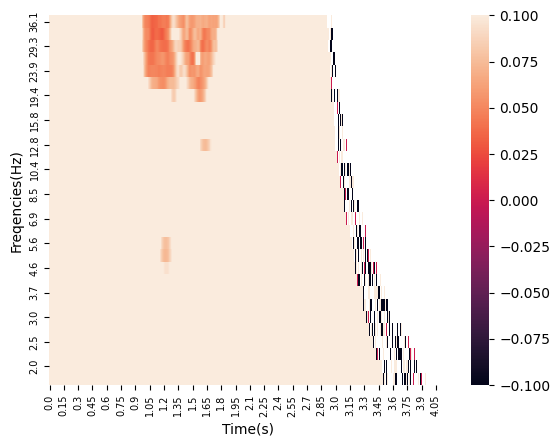

In [166]:
data=np.flipud(F_obs)
low_freq = 2                                                            #lower bound frequency interval
high_freq = 40                                                          #higher bound frequency interval
steps = 30
sample_rate = 200

freqs = list(np.logspace(np.log10(low_freq), np.log10(high_freq), steps))
freqs = np.flipud([round(freqs[x*2],1) for x in range(15)])

_, ax = plt.subplots()
sns.heatmap(data, ax=ax)
ax.set(xlabel="Time(s)", ylabel="Freqencies(Hz)")
print(ax.get_yticklabels())
ax.set_yticklabels(freqs, fontsize=7)
ax.set_xticklabels([round(x/sample_rate, 2) for x in ax.get_xticks()], fontsize=7)
plt.show()
